# 稀疏矩阵 ― sparse 模块

## 本章要学什么

科学与工程计算里经常出现绝大多数元素都是 0 的大矩阵，这叫稀疏矩阵，如果用 NumPy 的 `ndarray` 原样保存就会白白浪费内存；只保存非零元素既省内存，专用的算法也更快。

- 稀疏矩阵的保存格式(`dok_matrix`、`lil_matrix`、`coo_matrix`)
- 解稀疏矩阵的线性方程组(`spsolve()`)
- 快速组装系数矩阵的方法
- 用稀疏矩阵表示图并求最短路径(`csgraph.dijkstra()`)

In [1]:
import numpy as np
from matplotlib import pyplot as plt

import helper.magics
import helper.matplotlib
from scipy import sparse
from scipy.sparse import csgraph

## 稀疏矩阵的保存格式

`scipy.sparse` 里有几种表示稀疏矩阵的格式，用途各不相同，其中 `dok_matrix` 与 `lil_matrix` 适合逐个添加元素。

`dok_matrix` 继承自 `dict`，用字典保存非零元素：键是 (行, 列) 的元组，值是那个元素。单个元素的添加、删除、读取都很快，所以常见的用法是一点点把元素造出来，再转换成更快的格式。

In [2]:
from scipy import sparse

a = sparse.dok_matrix((10, 5))
a[2:5, 3] = 1.0, 2.0, 3.0
print(a.keys())
print(a.values())

dict_keys([(2, 3), (3, 3), (4, 3)])
dict_values([np.float64(1.0), np.float64(2.0), np.float64(3.0)])


`lil_matrix` 用两个列表保存非零元素：`data` 是各行的值，`rows` 是这些值所在的列。它同样能逐个添加元素，也能很快取出某一行的数据。

In [3]:
b = sparse.lil_matrix((10, 5))
b[2, 3] = 1.0
b[3, 4] = 2.0
b[3, 2] = 3.0
print(b.data)
print(b.rows)

[list([]) list([]) list([np.float64(1.0)])
 list([np.float64(3.0), np.float64(2.0)]) list([]) list([]) list([])
 list([]) list([]) list([])]
[list([]) list([]) list([3]) list([2, 4]) list([]) list([]) list([])
 list([]) list([]) list([])]


`coo_matrix` 用 `row`、`col`、`data` 三个数组保存非零元素，三者长度相同，分别放行、列和值。它不能读取或添加单个元素，造好之后要先转换成别的格式才能参与计算。

`coo_matrix` 允许同一个 (行, 列) 组合重复出现，转换成别的格式时这些重复的值会被加起来：下面的例子里 `(2, 3)` 上有 1 和 10 两个值，转换之后就变成 11。

稀疏矩阵的数据常常就以这种格式存在文件里，例如「用户 ID、商品 ID、评分」三列的 CSV，用 `loadtxt()` 或 `read_csv()` 读进来之后就能构成 `coo_matrix`。其中行是用户、列是商品、值是评分。

In [4]:
row = [2, 3, 3, 2]
col = [3, 4, 2, 3]
data = [1, 2, 3, 10]
c = sparse.coo_matrix((data, (row, col)), shape=(5, 6))
print(c.col, c.row, c.data)
print(c.toarray())

[3 4 2 3] [2 3 3 2] [ 1  2  3 10]
[[ 0  0  0  0  0  0]
 [ 0  0  0  0  0  0]
 [ 0  0  0 11  0  0]
 [ 0  0  3  0  2  0]
 [ 0  0  0  0  0  0]]


## 解大型线性方程组

用稀疏矩阵的线性代数可以解大型线性方程组，这里以全变分模型修复图像为例：左边是原图。右边是写上了白字的图，要把文字部分修补成接近周围浓淡的样子。

每一个要抹掉的像素对应一个未知数，让修补后的值等于上下左右 4 个像素的平均，式子如下。其中 $D_{i,j}$ 是 (i, j) 处像素的浓淡。

$$4 D_{i,j} - D_{i-1,j} - D_{i+1,j} - D_{i,j-1} - D_{i,j+1} = 0$$

$D_{i,j}$ 是未知数，而它周围的像素可能是已知、也可能是未知，所以一个式子里含 1 到 5 个未知数。

例如下左图里空白的格子是要修补的像素，给每个格子分配一个未知数 $X_i$ 就得到右图。$X_0$ 的式子如下。

$$4 X_0 - X_1 - X_3 = 2 + 3$$

$X_5$ 的式子则是下面这样。

$$4 X_5 - X_2 - X_6 - X_7 - X_4 = 0$$

把这 9 个式子联立求解，就能得到各处的浓淡，用 `numpy.linalg.solve()` 也能解。但未知数的个数与像素数相同，$100 \times 100$ 的区域就会出现 $10000 \times 10000$ 的系数矩阵。

由于系数矩阵是稀疏的，用 `spsolve()` 就能解得很快，需要准备的只有系数矩阵 $\mathbf{A}$ 与右端项 $\mathbf{b}$。

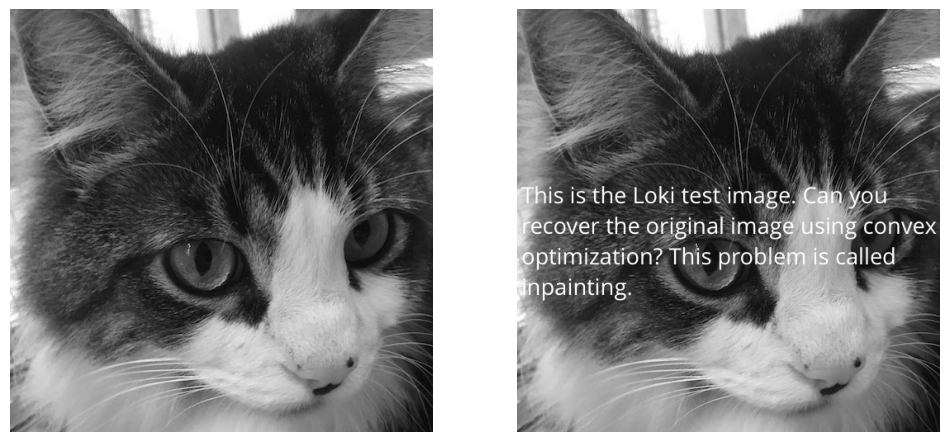

In [5]:
from pylab import imread

img1 = imread("data/loki512.png")
img2 = imread("data/loki512_corrupted.png")  # 写上文字的图像

fig, axes = plt.subplots(1, 2, figsize=(12, 6))
axes[0].imshow(img1, cmap="gray")
axes[1].imshow(img2, cmap="gray")
for ax in axes:
    ax.axis("off")
plt.show()

先由 `img1` 与 `img2` 找出浓淡不同的像素坐标 `Y`、`X`，这些就是要修补的像素。为了区分周围是未知数还是已知数，这里用一个与图像同形状的 `variables` 数组，把未知数的编号填进去，值为 `-1` 表示该像素是已知的。

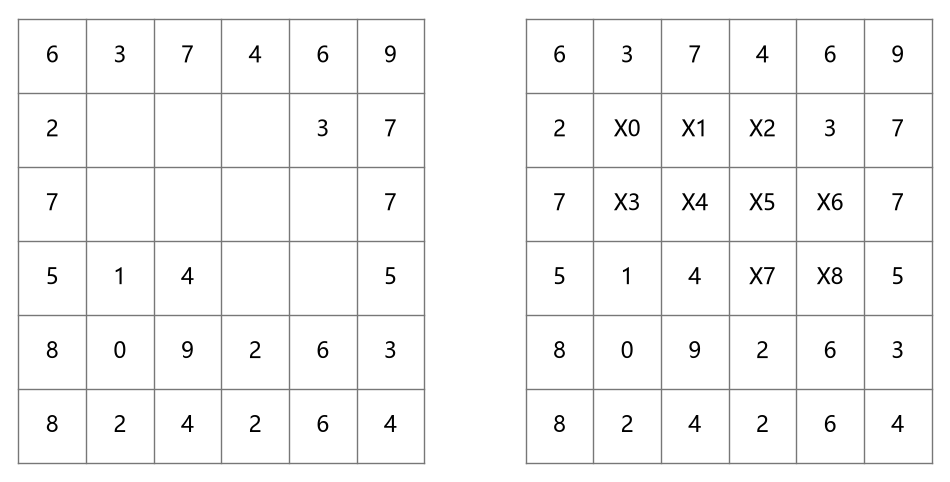

In [6]:
from helper.matplotlib import draw_grid

np.random.seed(42)
a = np.random.randint(0, 10, (6, 6)).astype(str)
a[1:3, 1:4] = ""
a[2:4, 3:5] = ""

iy, ix = np.where(a == "")
b = a.copy()
b[iy, ix] = ["X{}".format(i) for i in range(len(iy))]
fig, axes = plt.subplots(1, 2, figsize=(12, 6))
for ax in axes:
    ax.axis("off")
draw_grid(axes[0], a)
draw_grid(axes[1], b)
plt.show()

接下来往 `dok_matrix` 里逐个放元素：❶ 式子的编号与中心未知数的编号相同。所以系数矩阵的对角元素全是 4；❷ 用 `variables` 查出相邻像素的未知数编号；❸ 编号不小于 0 说明它是未知数。就把系数设为 -1；❹ 编号为 -1 说明它是已知的，就把它的浓淡加到右端项上。

In [7]:
Y, X = np.where(img1 != img2)
variables = np.full(img1.shape, -1, int)
variables[Y, X] = np.arange(len(X))

把两个矩阵用 `tocsc()` 转成 CSC 格式，再用 `spsolve()` 求解；把解写回图像对应的位置，就得到修补后的图像。下图左边是修补的结果，右边是它与原图的差。

In [8]:
%%time
A = sparse.dok_matrix((len(X), len(X)))
b = sparse.dok_matrix((len(X), 1))

neighbours = [(-1, 0), (1, 0), (0, -1), (0, 1)]

for v, (y, x) in enumerate(zip(Y, X)):
    A[v, v] = 4                                     # ❶ 対角要素
    for dy, dx in neighbours:
        y2, x2 = y + dy, x + dx
        v2 = variables[y2, x2]                       # ❷ 相邻像素的未知数编号
        if v2 >= 0:
            A[v, v2] = -1                            # ❸ 是未知数就把系数设为 -1
        else:
            b[v] += img2[y2, x2]                     # ❹ 是已知就加到右端项

CPU times: total: 3.2 s
Wall time: 3.31 s


往 `dok_matrix` 里一个个放元素并不算快，为了更快地组装系数矩阵，可以用下面的 `RCD` 类：`append()` 把行、列、值分别攒在三个列表里。

❶ 用 `broadcast_arrays()` 把参数广播。所以参数既可以是一维数组、也可以是单个数值；❷ 用 `tocoo()` 转成 `coo_matrix`；❸ 再用 `tocsc()` 转成 `csc_matrix`。由于 `coo_matrix` 会把重复下标的値加起来，右端项的累加就这样自然完成了。

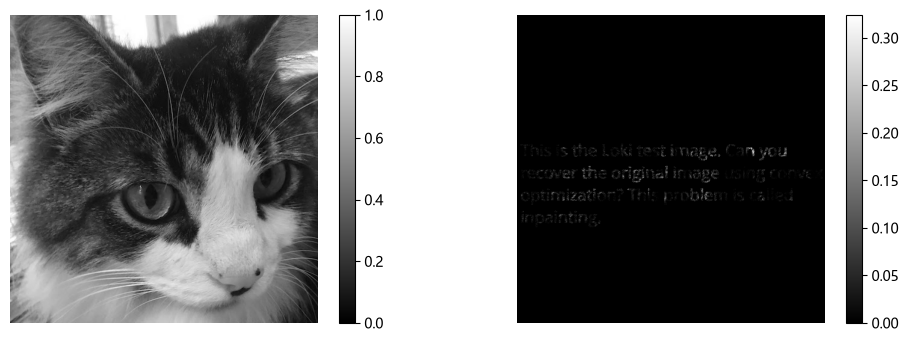

In [9]:
from scipy.sparse import linalg

Ac = A.tocsc()
bc = b.tocsc()

x = linalg.spsolve(Ac, bc)  # 解线性方程组

img3 = img2.copy()
img3[Y, X] = x  # 把解写回去

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
im = axes[0].imshow(img3, cmap="gray")
plt.colorbar(im, ax=axes[0])
im = axes[1].imshow(np.abs(img3 - img1), cmap="gray")
plt.colorbar(im, ax=axes[1])
for ax in axes:
    ax.axis("off")
plt.show()

用 `RCD` 组装系数矩阵：因为用的是 NumPy 的数组运算，只要对 4 个相邻方向循环一次即可，这个办法比往 `dok_matrix` 里逐个放元素快得多。

In [10]:
class RCD:
    """攒起行、列、值，做出 coo/csc 矩阵。"""

    def __init__(self, shape):
        self.row = []
        self.col = []
        self.dat = []
        self.shape = shape

    def append(self, r, c, d):
        r, c, d = np.broadcast_arrays(r, c, d)  #❶ 把形状对齐
        self.row.append(r)
        self.col.append(c)
        self.dat.append(d)

    def tocoo(self):  #❷ 变成 coo_matrix
        row = np.concatenate(self.row)
        col = np.concatenate(self.col)
        dat = np.concatenate(self.dat)
        return sparse.coo_matrix((dat, (row, col)), shape=self.shape)

    def tocsc(self):  #❸ 变成 csc_matrix
        return self.tocoo().tocsc()

解出来，并与前面的结果作比较。

In [11]:
%%time
V = np.arange(len(X))

A = RCD((len(X), len(X)))
b = RCD((len(X), 1))

A.append(V, V, 4)

for dy, dx in neighbours:
    Y2, X2 = Y + dy, X + dx
    V2 = variables[Y2, X2]
    D2 = img2[Y2, X2]

    mask = V2 >= 0
    nmask = ~mask
    A.append(V[mask], V2[mask], -1)
    b.append(V[nmask], 0, D2[nmask])

Ac = A.tocsc()
bc = b.tocsc()

CPU times: total: 15.6 ms
Wall time: 27.6 ms


## 最短路径

用稀疏矩阵 `w` 可以表示图：`w[i, j]` 是节点 i 与节点 j 之间边的权重，没有边的组合就不放进稀疏矩阵。稀疏矩阵按数组显示时那些位置是 0，但这并不表示有一条权重为 0 的边。如果是无向图，只要在 `w[i, j]` 与 `w[j, i]` 中放一个就够了。

```{mermaid}
flowchart LR
A --10--> B
B --5--> C
A --3--> C
C --7--> D
D --4--> A
D --6--> C
```

给 A、B、C、D 编上 0、1、2、3 号，构成稀疏矩阵。

In [12]:
x2 = linalg.spsolve(Ac, bc)
np.allclose(x, x2)

True

用 `csgraph` 模块求最短路径。

下左图是一张迷宫，黑线是用 `csgraph` 求出的最短路径：❶ 为了便于计算，先按阈值把彩色迷宫转成二值图，黑色是墙、白色是通路；❷ 为了避免把迷宫外侧的空白误当成通路，在中央的两侧画两条黑线，把空白分成上下两部分，处理后的迷宫就是右图。

In [13]:
w = sparse.dok_matrix((4, 4))

edges = [(0, 1, 10), (1, 2, 5), (0, 2, 3), (2, 3, 7), (3, 0, 4), (3, 2, 6)]

for i, j, v in edges:
    w[i, j] = v

w.todense()

matrix([[ 0., 10.,  3.,  0.],
        [ 0.,  0.,  5.,  0.],
        [ 0.,  0.,  0.,  7.],
        [ 4.,  0.,  6.,  0.]])

把迷宫的每个像素当作图的一个节点，节点编号与坐标的关系是 `idx = y * W + x`。

❶ 先找出所有上下相邻的白色像素对与左右相邻的白色像素对，把节点编号的组合排进 `edges`；❷ 再用 `coo_matrix()` 造出稀疏矩阵，把所有边的权重都设为 1。

In [14]:
img = plt.imread("data/maze.png")
sx, sy = (400, 979)
ex, ey = (398, 25)
bimg = np.all(img > 0.81, axis=2)  #❶ 把白色当作通路
H, W = bimg.shape

x0, x1 = np.where(bimg[H // 2, :] == 0)[0][[0, -1]]  #❷ 中央那堵墙的两端
bimg[H // 2, :x0] = 0
bimg[H // 2, x1:] = 0

用 `csgraph.dijkstra()` 计算从 `startid` 节点到其他所有节点的最短距离：`directed=False` 表示无向图，`return_predecessors=True` 则连追溯路径用的信息一起返回。`d` 与 `p` 的形状都是 (起点个数, 节点数)。

In [15]:
# 上下相邻的白色像素
mask = bimg[1:, :] & bimg[:-1, :]
idx = np.where(mask.ravel())[0]
vedge = np.c_[idx, idx + W]

# 左右相邻的白色像素
mask = bimg[:, 1:] & bimg[:, :-1]
y, x = np.where(mask)
idx = y * W + x
hedge = np.c_[idx, idx + 1]

edges = np.vstack([vedge, hedge])  #❶ 所有的边

values = np.ones(edges.shape[0])
w = sparse.coo_matrix(
    (values, (edges[:, 0], edges[:, 1])), shape=(bimg.size, bimg.size)  #❷
)

`d[i, j]` 是从 `indices[i]` 节点到节点 j 的距离，没有路径时是 `inf`。数一数到达不了的节点，就能知道墙的像素以及被墙围起来的区域的数目。

In [16]:
from scipy.sparse import csgraph

startid = sy * W + sx  # 起点的节点编号
endid = ey * W + ex    # 终点的节点编号
d, p = csgraph.dijkstra(w, indices=[startid], return_predecessors=True, directed=False)
%C d.shape; p.shape

  d.shape      p.shape  
-----------  -----------
(1, 801600)  (1, 801600)


`p[i, j]` 是从 `indices[i]` 到节点 j 的路径上、紧接在 j 之前的那个节点：从 `endid` 沿 `p` 一直回到 `startid`，把经过的节点排起来就是路径，最后再翻转一次。

In [17]:
np.isinf(d[0]).sum()

np.int64(322324)

在原迷宫图像上把 `path` 的像素涂黑。

In [18]:
path = []
node_id = endid
while True:
    path.append(node_id)
    if node_id == startid or node_id < 0:
        break
    node_id = p[0, node_id]
path = np.array(path)

在这张迷宫里，相邻白色像素之间的权重都是 1，所以求出的路径就是最短的。在游戏地图里，权重常常随地形而变，那种情况下要按地形分别定权重，权重总和最小的路径才是最优路径。

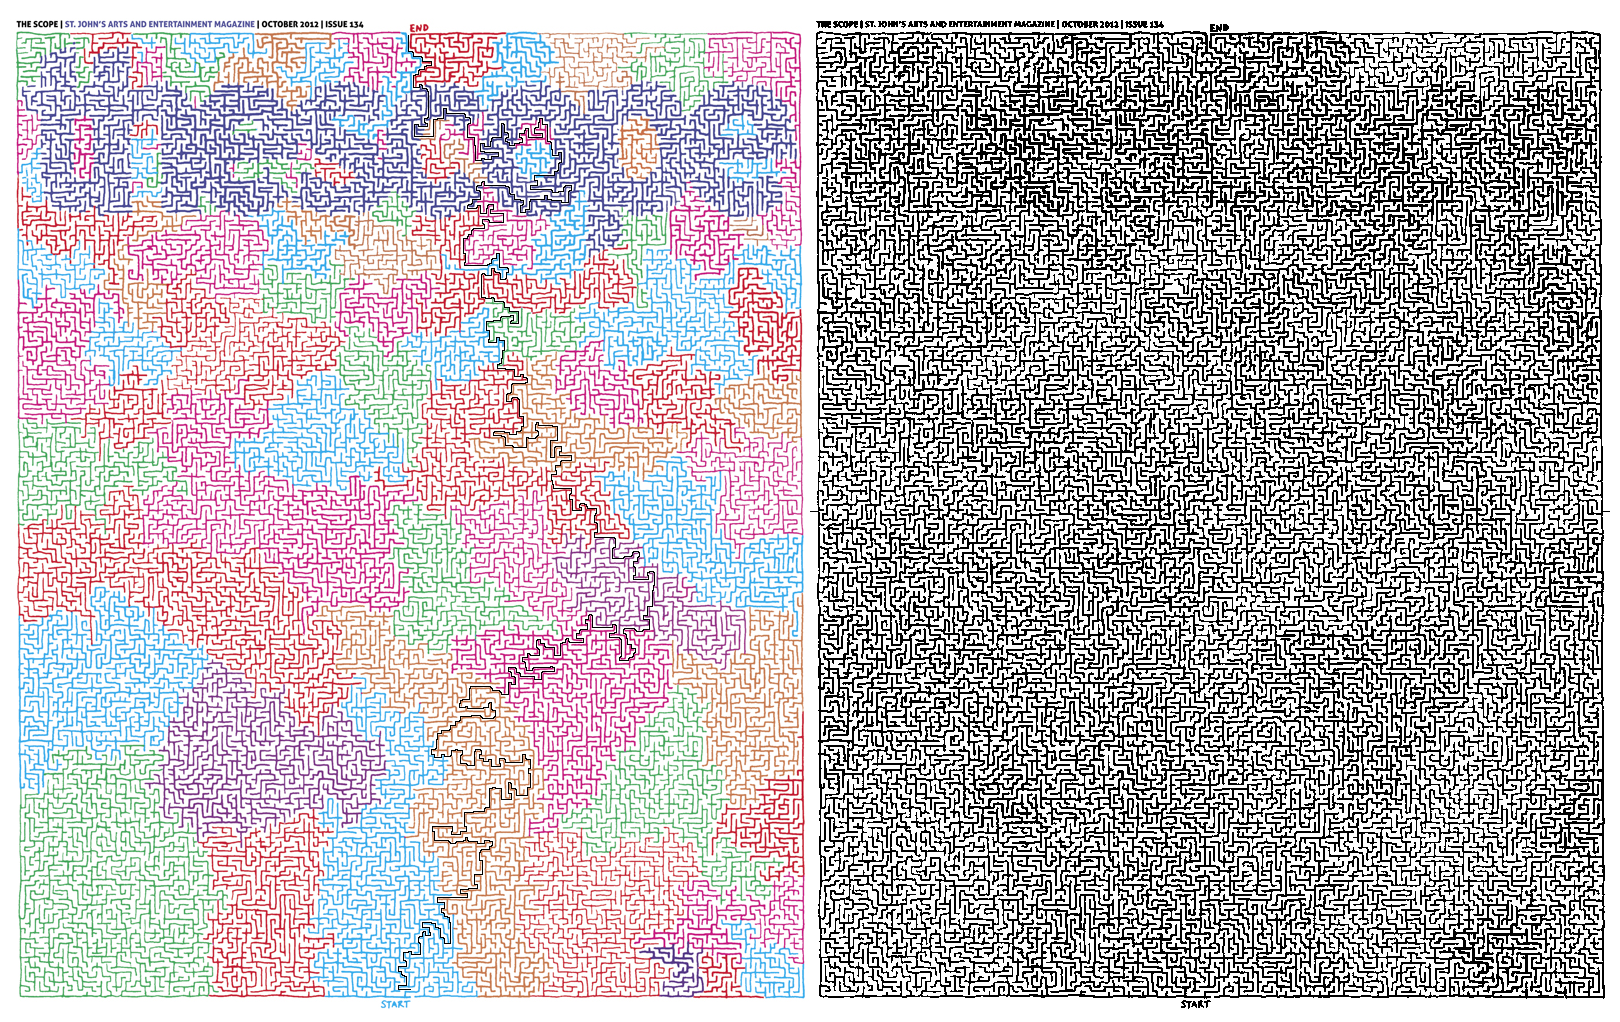

In [19]:
x, y = path % W, path // W
img[y, x, :] = 0  # 用黑色画出路径
fig, axes = plt.subplots(1, 2, figsize=(16, 12))
axes[0].imshow(img)
axes[1].imshow(bimg, cmap="gray")
for ax in axes:
    ax.axis("off")
fig.subplots_adjust(0, 0, 1, 1, 0, 0)
plt.show()

在这张迷宫里，相邻白色像素之间的权重都是 1。所以求出的路径就是最短的。在游戏地图里，权重常常随地形而变，那种情况下要按地形分别定权重，权重总和最小的路径才是最优路径。

## 小结

* 稀疏矩阵只保存非零元素：逐个添加时用 `dok_matrix` 或 `lil_matrix`，一次造好时用 `coo_matrix`。
* `coo_matrix` 会把重复下标的値加起来，适合先收集数据再构造。
* 大型线性方程组用 `spsolve()` 解，系数矩阵用数组运算一次组装会快很多。
* 用稀疏矩阵可以表示图，再用 `csgraph.dijkstra()` 求最短路径。